# Concept Drift (Desviación conceptual)

Notebook práctico para acompañar la clase sobre **Concept Drift**.

La clase parte de una idea sencilla: así como una taza de café puede cambiar de sabor de un día para otro por cambios en el barista, el lote, el agua, la higiene o el contexto, los datos y las relaciones aprendidas por un modelo también pueden cambiar después del despliegue.

**Objetivos del notebook**

1. Simular diferentes tipos de concept drift.
2. Visualizar cambios en distribuciones y fronteras de decisión.
3. Entrenar modelos antes y después del drift.
4. Detectar drift con pruebas estadísticas y monitoreo de error.
5. Aplicar una estrategia simple de adaptación/reentrenamiento.

> Definición guía: existe concept drift cuando la distribución conjunta cambia con el tiempo:  
> $P_{t_0}(X, y) \neq P_{t_1}(X, y)$

## 1. Preparación del entorno

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import ks_2samp

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

plt.rcParams["figure.figsize"] = (8, 5)

## 2. Intuición: los datos cambian porque la realidad cambia

En producción, el modelo no vive en un laboratorio. Recibe datos nuevos, afectados por usuarios, sensores, estaciones, economía, campañas, modas, pandemias o cambios operativos.

En esta sección simularemos un escenario simple de clasificación binaria.

In [ ]:
def generate_stream(n=2000, drift_point=1000, drift_type="real", random_state=42):
    """Genera un flujo de datos con drift.

    drift_type:
    - 'none': sin drift
    - 'virtual': cambia P(X), pero se mantiene P(y|X) aproximadamente
    - 'real': cambia P(y|X), es decir, cambia la frontera de decisión
    """
    rng = np.random.default_rng(random_state)
    X = rng.normal(0, 1, size=(n, 2))

    # Concepto inicial: y depende de x1 + x2
    logits_0 = X[:, 0] + X[:, 1]
    y = (logits_0 > 0).astype(int)

    if drift_type == "virtual":
        # Cambia la distribución de entrada luego del drift
        X[drift_point:] += np.array([1.5, -1.0])
        logits = X[:, 0] + X[:, 1]
        y = (logits > 0).astype(int)

    elif drift_type == "real":
        # Cambia la relación entre X e y luego del drift
        logits_1 = X[:, 0] - X[:, 1]
        y[drift_point:] = (logits_1[drift_point:] > 0).astype(int)

    elif drift_type == "none":
        pass
    else:
        raise ValueError("drift_type debe ser 'none', 'virtual' o 'real'")

    # Pequeño ruido de etiqueta
    noise_idx = rng.choice(n, size=int(0.03 * n), replace=False)
    y[noise_idx] = 1 - y[noise_idx]

    time = np.arange(n)
    return X, y, time

X_real, y_real, time = generate_stream(drift_type="real")
X_virtual, y_virtual, _ = generate_stream(drift_type="virtual")

## 3. Visualización de drift real y drift virtual

- **Drift real:** cambia $P(y\mid X)$. La regla que conecta entradas y salida deja de ser la misma.
- **Drift virtual:** cambia $P(X)$, pero la relación $P(y\mid X)$ se mantiene.

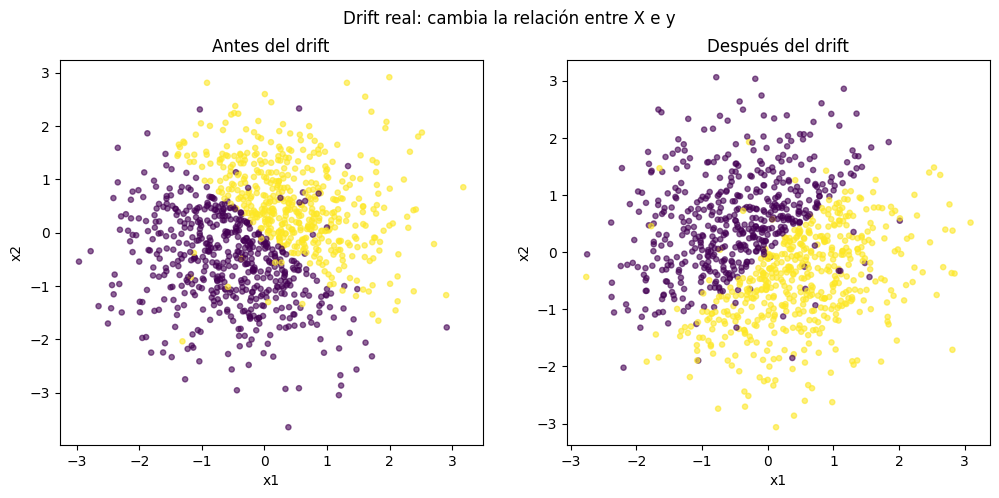

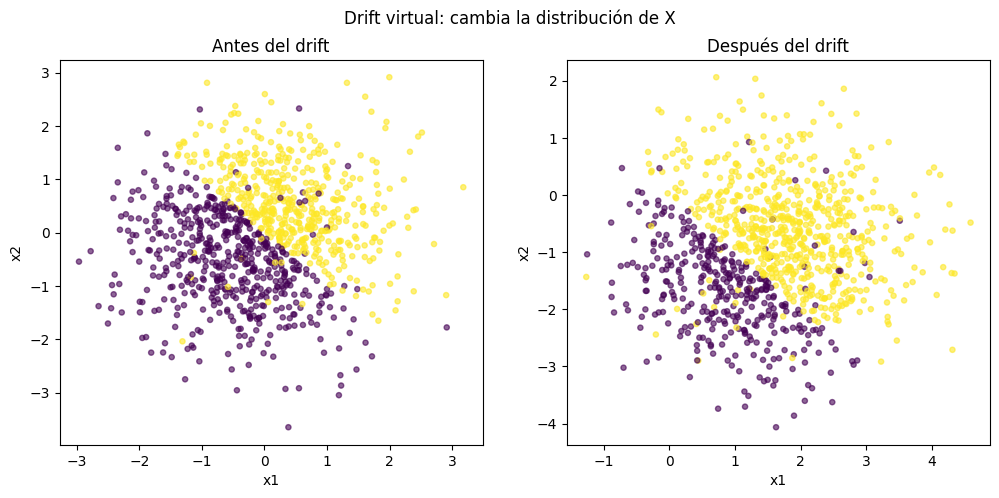

In [ ]:
def plot_before_after(X, y, drift_point=1000, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    parts = [(slice(0, drift_point), "Antes del drift"), (slice(drift_point, None), "Después del drift")]
    for ax, (idx, subtitle) in zip(axes, parts):
        ax.scatter(X[idx, 0], X[idx, 1], c=y[idx], s=14, alpha=0.6)
        ax.set_title(subtitle)
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")
    fig.suptitle(title)
    plt.show()

plot_before_after(X_real, y_real, title="Drift real: cambia la relación entre X e y")
plot_before_after(X_virtual, y_virtual, title="Drift virtual: cambia la distribución de X")

## 4. Consecuencia: un modelo entrenado en el pasado puede volverse obsoleto

Entrenaremos un modelo usando solo datos antes del drift y evaluaremos su desempeño antes y después del cambio.

In [ ]:
def evaluate_pre_post(X, y, drift_point=1000):
    X_train, y_train = X[:drift_point], y[:drift_point]
    X_test_pre, y_test_pre = X[:drift_point], y[:drift_point]
    X_test_post, y_test_post = X[drift_point:], y[drift_point:]

    model = make_pipeline(StandardScaler(), LogisticRegression())
    model.fit(X_train, y_train)

    pred_pre = model.predict(X_test_pre)
    pred_post = model.predict(X_test_post)

    return pd.DataFrame({
        "Periodo": ["Antes del drift", "Después del drift"],
        "Accuracy": [accuracy_score(y_test_pre, pred_pre), accuracy_score(y_test_post, pred_post)],
        "Balanced accuracy": [balanced_accuracy_score(y_test_pre, pred_pre), balanced_accuracy_score(y_test_post, pred_post)]
    })

print("Modelo entrenado antes del drift real")
evaluate_pre_post(X_real, y_real)

Modelo entrenado antes del drift real


,Periodo,Accuracy,Balanced accuracy
0,Antes del drift,0.967,0.966858
1,Después del drift,0.491,0.491024


In [ ]:
print("Modelo entrenado antes del drift virtual")
evaluate_pre_post(X_virtual, y_virtual)

Modelo entrenado antes del drift virtual


,Periodo,Accuracy,Balanced accuracy
0,Antes del drift,0.967,0.966858
1,Después del drift,0.955,0.953756


**Pregunta para discusión:** ¿por qué el drift real suele ser más peligroso para la validez predictiva que el drift virtual?

## 5. Formas de cambio temporal

La clase menciona varias formas de variación: cambios repentinos, lentos, graduales, recurrentes y valores atípicos. Simularemos una señal de desempeño para visualizar estas formas.

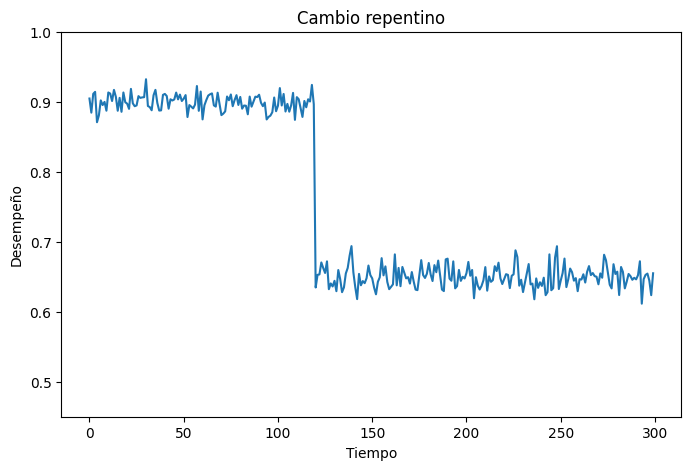

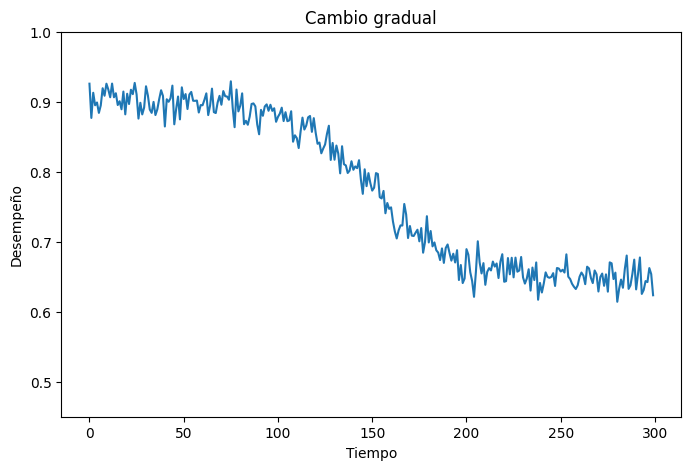

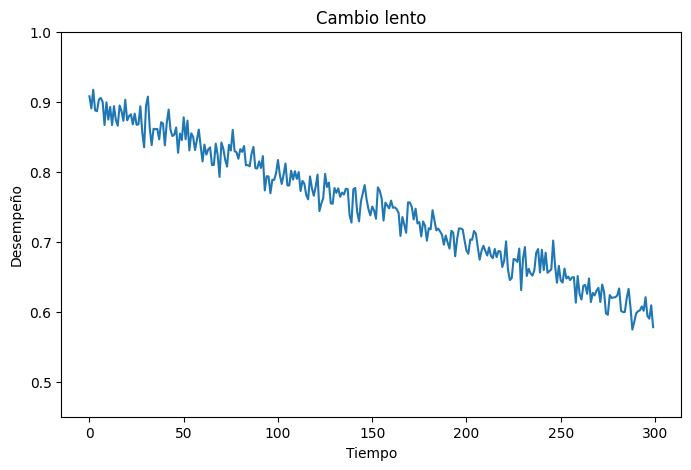

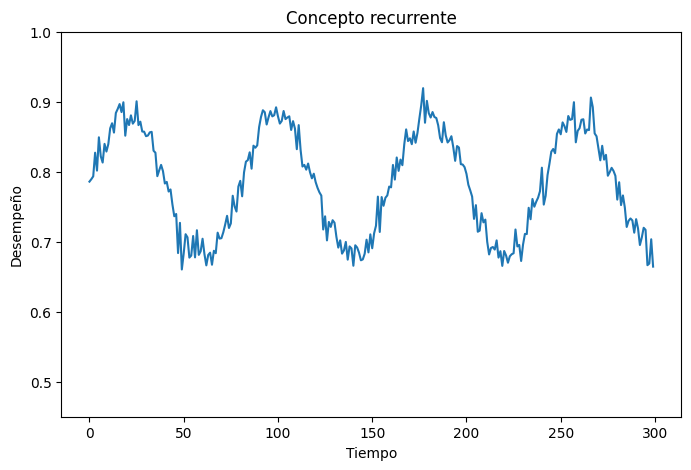

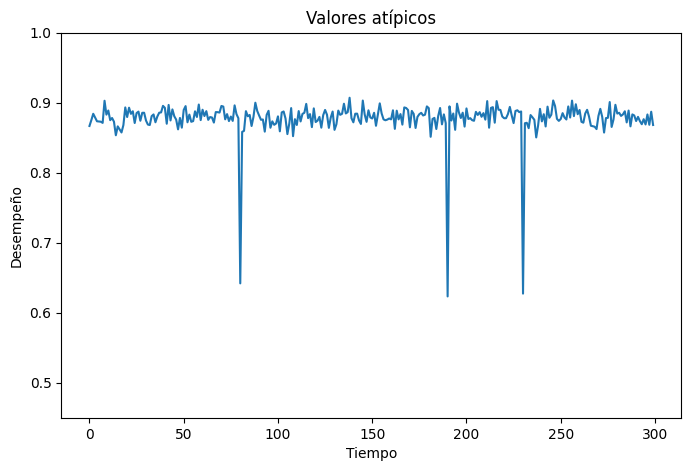

In [ ]:
n = 300
t = np.arange(n)

abrupt = np.where(t < 120, 0.9, 0.65) + rng.normal(0, 0.015, n)
gradual = 0.9 - 0.25 / (1 + np.exp(-(t - 150) / 20)) + rng.normal(0, 0.015, n)
slow = 0.9 - 0.001 * t + rng.normal(0, 0.015, n)
recurrent = 0.78 + 0.10 * np.sin(2 * np.pi * t / 80) + rng.normal(0, 0.015, n)
outlier = np.repeat(0.88, n) + rng.normal(0, 0.01, n)
outlier[[80, 190, 230]] -= 0.25

signals = {
    "Cambio repentino": abrupt,
    "Cambio gradual": gradual,
    "Cambio lento": slow,
    "Concepto recurrente": recurrent,
    "Valores atípicos": outlier
}

for name, values in signals.items():
    plt.figure()
    plt.plot(t, values)
    plt.ylim(0.45, 1.0)
    plt.xlabel("Tiempo")
    plt.ylabel("Desempeño")
    plt.title(name)
    plt.show()

## 6. Detección informada basada en distribución

Una estrategia informada es comparar datos antiguos vs. datos recientes. Aquí usamos la prueba Kolmogorov-Smirnov para detectar si una variable cambió su distribución.

Esta estrategia no necesita etiquetas, pero puede detectar cambios que no necesariamente afectan la tarea predictiva.

In [ ]:
def ks_drift_report(X, drift_point=1000, feature_names=("x1", "x2")):
    rows = []
    for j, name in enumerate(feature_names):
        stat, pvalue = ks_2samp(X[:drift_point, j], X[drift_point:, j])
        rows.append({"Variable": name, "KS statistic": stat, "p-value": pvalue, "Drift detectado (p<0.05)": pvalue < 0.05})
    return pd.DataFrame(rows)

print("Drift real")
display(ks_drift_report(X_real))

print("Drift virtual")
display(ks_drift_report(X_virtual))

Drift real


,Variable,KS statistic,p-value,Drift detectado (p<0.05)
0,x1,0.053,0.120515,False
1,x2,0.036,0.536277,False


Drift virtual


,Variable,KS statistic,p-value,Drift detectado (p<0.05)
0,x1,0.581,1.484083e-156,True
1,x2,0.388,1.614349e-67,True


## 7. Detección informada basada en tasa de error

Otra estrategia es monitorear el error del modelo. Esta estrategia es más cercana al impacto real del drift, pero requiere etiquetas verdaderas o feedback confiable.

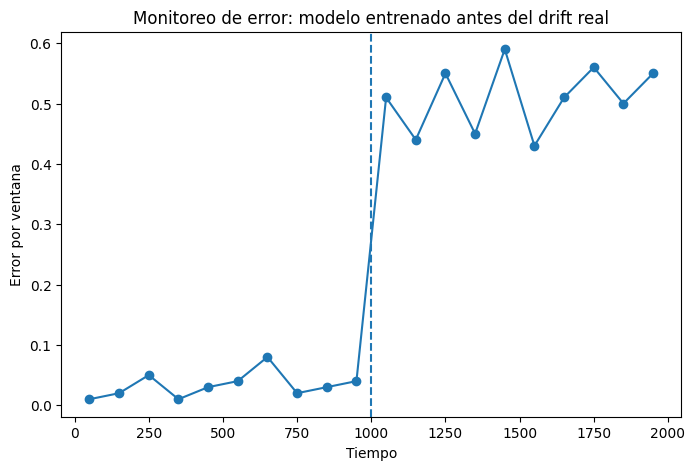

,centro_ventana,error
0,50,0.01
1,150,0.02
2,250,0.05
3,350,0.01
4,450,0.03
5,550,0.04
6,650,0.08
7,750,0.02
8,850,0.03
9,950,0.04


In [ ]:
def rolling_error_monitor(X, y, drift_point=1000, window=100):
    model = make_pipeline(StandardScaler(), LogisticRegression())
    model.fit(X[:drift_point], y[:drift_point])

    errors = []
    centers = []
    for start in range(0, len(y) - window + 1, window):
        end = start + window
        y_pred = model.predict(X[start:end])
        error = 1 - accuracy_score(y[start:end], y_pred)
        errors.append(error)
        centers.append((start + end) // 2)
    return np.array(centers), np.array(errors)

centers, errors = rolling_error_monitor(X_real, y_real)

plt.figure()
plt.plot(centers, errors, marker="o")
plt.axvline(1000, linestyle="--")
plt.xlabel("Tiempo")
plt.ylabel("Error por ventana")
plt.title("Monitoreo de error: modelo entrenado antes del drift real")
plt.show()

pd.DataFrame({"centro_ventana": centers, "error": errors})

## 8. Detector simple tipo Page-Hinkley

Page-Hinkley acumula desviaciones respecto a una media esperada. Cuando la desviación acumulada supera un umbral, se dispara una alerta.

Aquí lo usamos sobre la secuencia de errores por ventana.

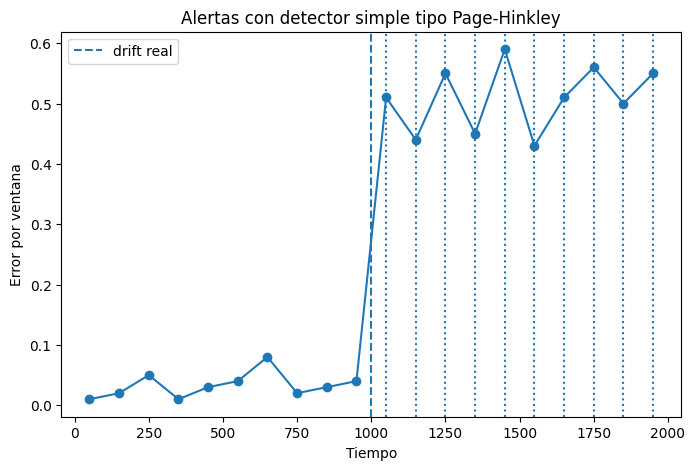

Alertas detectadas en tiempos aproximados: [1050, 1150, 1250, 1350, 1450, 1550, 1650, 1750, 1850, 1950]


In [ ]:
def page_hinkley(values, delta=0.005, threshold=0.08):
    mean = 0.0
    cumulative = 0.0
    min_cumulative = 0.0
    alarms = []

    for i, x in enumerate(values):
        mean = mean + (x - mean) / (i + 1)
        cumulative += x - mean - delta
        min_cumulative = min(min_cumulative, cumulative)
        if cumulative - min_cumulative > threshold:
            alarms.append(i)
            cumulative = 0.0
            min_cumulative = 0.0
    return alarms

alarms = page_hinkley(errors, threshold=0.08)
alarm_times = centers[alarms]

plt.figure()
plt.plot(centers, errors, marker="o")
plt.axvline(1000, linestyle="--", label="drift real")
for at in alarm_times:
    plt.axvline(at, linestyle=":")
plt.xlabel("Tiempo")
plt.ylabel("Error por ventana")
plt.title("Alertas con detector simple tipo Page-Hinkley")
plt.legend()
plt.show()

print("Alertas detectadas en tiempos aproximados:", alarm_times.tolist())

## 9. Estrategia adaptativa: reentrenar con datos recientes

Una acción común después de detectar drift es descartar parte de los datos antiguos y reentrenar con una ventana reciente. Esta idea conecta con estrategias de **olvido** y **detectores con trigger**.

In [ ]:
def adaptive_retraining_demo(X, y, drift_point=1000, retrain_start=1000, recent_window=500):
    # Modelo viejo: entrenado solo antes del drift
    old_model = make_pipeline(StandardScaler(), LogisticRegression())
    old_model.fit(X[:drift_point], y[:drift_point])

    # Modelo adaptado: reentrenado con una ventana reciente después del drift
    new_model = make_pipeline(StandardScaler(), LogisticRegression())
    start = max(0, retrain_start - recent_window // 2)
    end = min(len(y), retrain_start + recent_window // 2)
    new_model.fit(X[start:end], y[start:end])

    X_eval, y_eval = X[drift_point:], y[drift_point:]
    old_pred = old_model.predict(X_eval)
    new_pred = new_model.predict(X_eval)

    return pd.DataFrame({
        "Modelo": ["Modelo original", "Modelo adaptado"],
        "Accuracy post-drift": [accuracy_score(y_eval, old_pred), accuracy_score(y_eval, new_pred)],
        "Balanced accuracy post-drift": [balanced_accuracy_score(y_eval, old_pred), balanced_accuracy_score(y_eval, new_pred)]
    })

adaptive_retraining_demo(X_real, y_real)

## 10. Aprendizaje incremental con olvido

Los métodos ciegos no esperan una alarma explícita. Se actualizan continuamente. En este ejemplo usamos `SGDClassifier` con `partial_fit`, procesando el flujo por bloques.

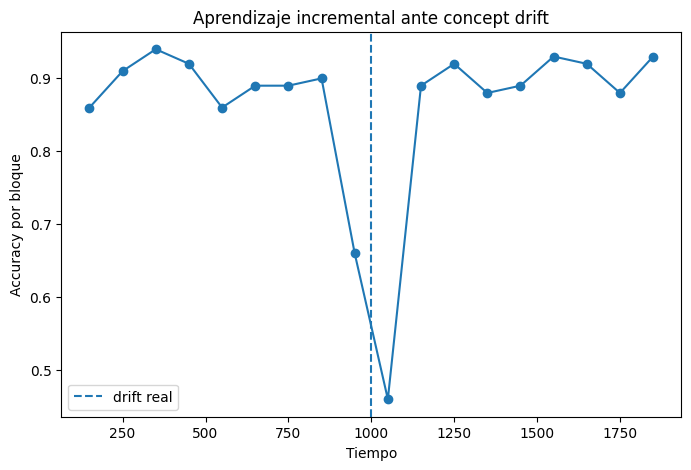

In [ ]:
def incremental_learning_stream(X, y, batch_size=100):
    classes = np.array([0, 1])
    scaler = StandardScaler()
    clf = SGDClassifier(loss="log_loss", random_state=RANDOM_STATE)

    accuracies = []
    batch_centers = []

    # Inicialización con el primer bloque
    X0, y0 = X[:batch_size], y[:batch_size]
    scaler.partial_fit(X0)
    clf.partial_fit(scaler.transform(X0), y0, classes=classes)

    for start in range(batch_size, len(y) - batch_size, batch_size):
        end = start + batch_size
        X_batch, y_batch = X[start:end], y[start:end]

        y_pred = clf.predict(scaler.transform(X_batch))
        accuracies.append(accuracy_score(y_batch, y_pred))
        batch_centers.append((start + end) // 2)

        # Actualización incremental después de observar el bloque
        scaler.partial_fit(X_batch)
        clf.partial_fit(scaler.transform(X_batch), y_batch)

    return np.array(batch_centers), np.array(accuracies)

centers_inc, acc_inc = incremental_learning_stream(X_real, y_real)

plt.figure()
plt.plot(centers_inc, acc_inc, marker="o")
plt.axvline(1000, linestyle="--", label="drift real")
plt.xlabel("Tiempo")
plt.ylabel("Accuracy por bloque")
plt.title("Aprendizaje incremental ante concept drift")
plt.legend()
plt.show()

## 11. Ejercicio práctico para estudiantes

Modifica el código anterior para responder:

1. ¿Qué pasa si el drift ocurre en el tiempo 500 en lugar de 1000?
2. ¿Qué detector genera menos falsas alarmas?
3. ¿Qué estrategia funciona mejor: reentrenar con todo el histórico o solo con datos recientes?
4. ¿Qué ocurre cuando no hay etiquetas verdaderas disponibles?
5. Diseña un caso de concept drift para salud, educación, retail, banca o sensores IoT.

## 12. Conclusiones

El concept drift es una propiedad natural de sistemas desplegados: los datos reflejan la realidad, y la realidad cambia. Por eso, un modelo no debe considerarse terminado en el momento del despliegue. Debe monitorearse, auditarse y actualizarse.

La estrategia adecuada depende del contexto: disponibilidad de etiquetas, velocidad del flujo, costo del error, recurrencia de patrones y capacidad de cómputo. En producción, detectar drift no basta; lo importante es conectar la alerta con una acción confiable.